In [1]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt


Tracts matched: 1772
Original jobs: 3288681
Jobs after spatial join: 3288681


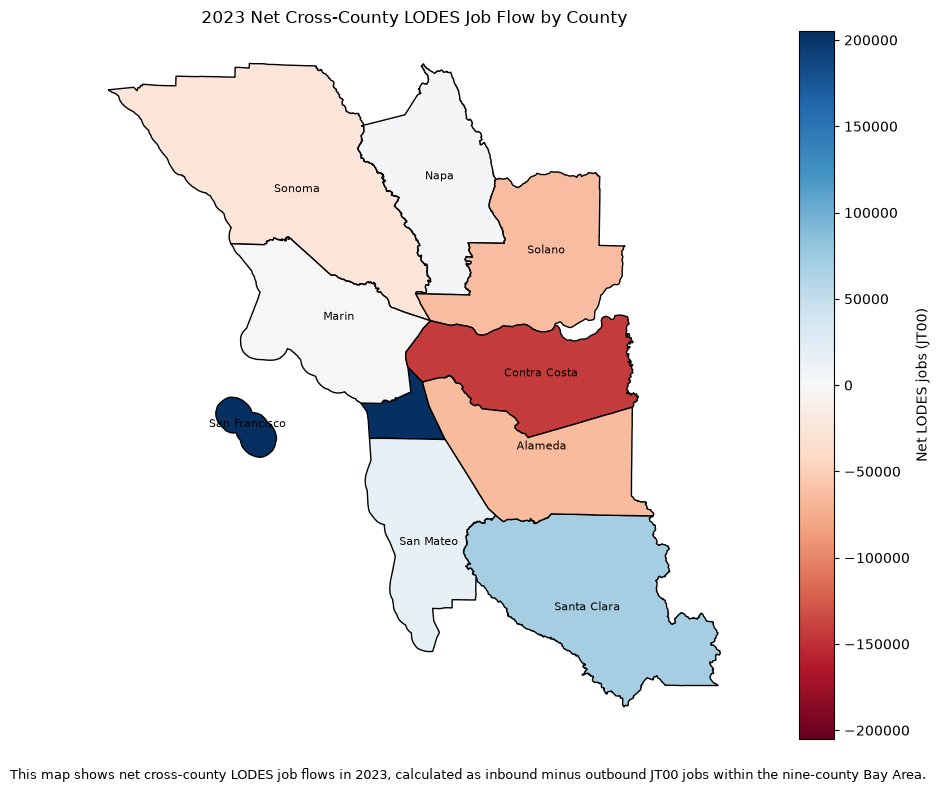

In [2]:
tracts = gpd.read_file("../data/raw/boundaries/tl_2023_06_tract.zip")
counties = gpd.read_file("../data/raw/boundaries/tl_2023_us_county.zip")

codes = ["001", "013", "041", "055", "075", "081", "085", "095", "097"]

tracts = tracts[
    (tracts["STATEFP"] == "06") &
    (tracts["COUNTYFP"].isin(codes))
].to_crs(epsg=2227)

counties = counties[
    (counties["STATEFP"] == "06") &
    (counties["COUNTYFP"].isin(codes))
].to_crs(epsg=2227)

tract_points = tracts[["GEOID", "geometry"]].copy()
tract_points["geometry"] = tracts.representative_point()

matched = gpd.sjoin(
    tract_points,
    counties[["NAME", "geometry"]],
    how="inner",
    predicate="within"
)

tract_county = matched[["GEOID", "NAME"]]

jobs = pd.read_csv(
    "../data/processed/LODES_2023_tract.csv",
    dtype={"w_tract": str, "h_tract": str}
)

home = tract_county.rename(
    columns={"GEOID": "h_tract", "NAME": "h_county"}
)

work = tract_county.rename(
    columns={"GEOID": "w_tract", "NAME": "w_county"}
)

flows = jobs[["h_tract", "w_tract", "commuters"]]
flows = flows.merge(home, on="h_tract")
flows = flows.merge(work, on="w_tract")

print("Tracts matched:", len(matched))
print("Original jobs:", jobs["commuters"].sum())
print("Jobs after spatial join:", flows["commuters"].sum())

cross_county = flows[flows["h_county"] != flows["w_county"]]

inbound = cross_county.groupby("w_county")["commuters"].sum()
outbound = cross_county.groupby("h_county")["commuters"].sum()
net = (inbound - outbound).rename("net")

county_map = counties.merge(net, left_on="NAME", right_index=True)

max_net = county_map["net"].abs().max()

fig, ax = plt.subplots(figsize=(10, 8))

county_map.plot(
    column="net",
    ax=ax,
    cmap="RdBu",
    vmin=-max_net,
    vmax=max_net,
    legend=True,
    legend_kwds={"label": "Net LODES jobs (JT00)"},
    edgecolor="black"
)

for _, row in county_map.iterrows():
    point = row.geometry.representative_point()
    ax.text(point.x, point.y, row["NAME"], ha="center", fontsize=8)

ax.set_title("2023 Net Cross-County LODES Job Flow by County")
ax.axis("off")

fig.text(
    0.5, 0.02,
    "This map shows net cross-county LODES job flows in 2023, calculated as inbound minus outbound JT00 jobs within the nine-county Bay Area.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=(0, 0.05, 1, 1))

os.makedirs("../visualizations/figures", exist_ok=True)
plt.savefig("../visualizations/figures/map_2023_net_county_flow.png", dpi=200, bbox_inches="tight")
plt.show()

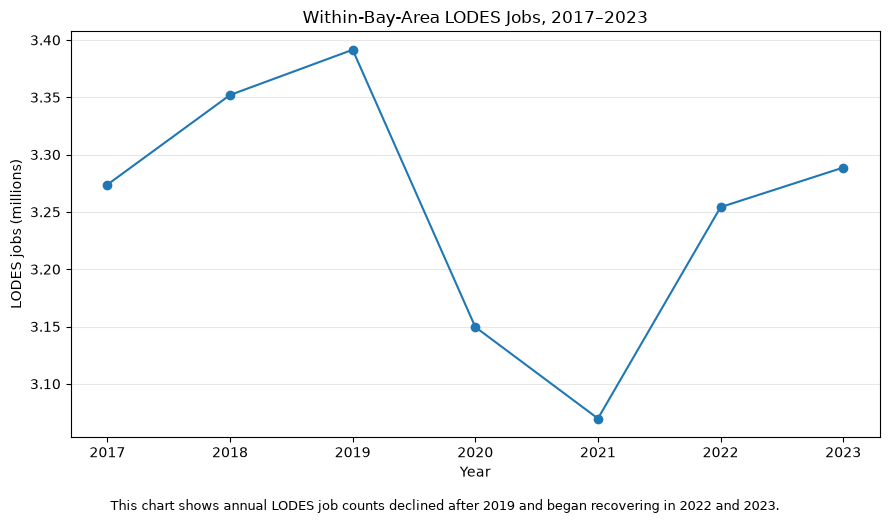

In [3]:
years = range(2017, 2024)
annual_jobs = []

for year in years:
    file_path = f"../data/processed/LODES_{year}_county.csv"
    df = pd.read_csv(file_path)

    total_jobs = df["commuters"].sum()

    annual_jobs.append({
        "year": year,
        "jobs": total_jobs
    })

annual_jobs = pd.DataFrame(annual_jobs)

os.makedirs("../visualizations/figures", exist_ok=True)

plt.figure(figsize=(9, 5))

plt.plot(
    annual_jobs["year"],
    annual_jobs["jobs"] / 1_000_000,
    marker="o"
)

plt.title("Within-Bay-Area LODES Jobs, 2017–2023")
plt.xlabel("Year")
plt.ylabel("LODES jobs (millions)")
plt.xticks(list(years))
plt.grid(axis="y", alpha=0.3)

plt.figtext(
    0.5,
    -0.03,
    "This chart shows annual LODES job counts declined after 2019 and began recovering in 2022 and 2023.",
    ha="center",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    "../visualizations/figures/chart1_annual_lodes_jobs.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

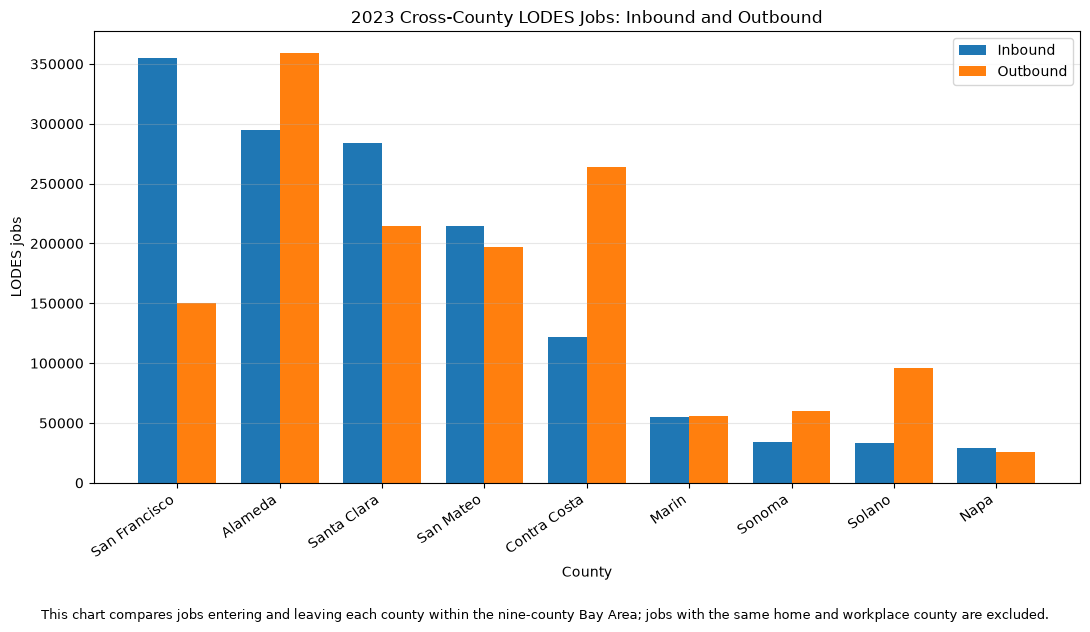

In [4]:
file_path = "../data/processed/LODES_2023_county.csv"
county_2023 = pd.read_csv(file_path)

cross_county = county_2023[county_2023["w_county"] != county_2023["h_county"]]

inbound = (cross_county.groupby("w_county")["commuters"].sum())

outbound = (cross_county.groupby("h_county")["commuters"].sum())

county_flows = pd.concat([inbound.rename("inbound"), outbound.rename("outbound")], axis=1).fillna(0)

county_flows = county_flows.sort_values("inbound", ascending=False)

x = np.arange(len(county_flows))
width = 0.38

os.makedirs("../visualizations/figures", exist_ok=True)

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    county_flows["inbound"],
    width,
    label="Inbound"
)

plt.bar(
    x + width / 2,
    county_flows["outbound"],
    width,
    label="Outbound"
)

plt.title("2023 Cross-County LODES Jobs: Inbound and Outbound")
plt.xlabel("County")
plt.ylabel("LODES jobs")
plt.xticks(
    x,
    county_flows.index,
    rotation=35,
    ha="right"
)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.figtext(
    0.5,
    -0.04,
    "This chart compares jobs entering and leaving each county within the nine-county Bay Area; jobs with the same home and workplace county are excluded.",
    ha="center",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    "../visualizations/figures/chart2_2023_inbound_outbound.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

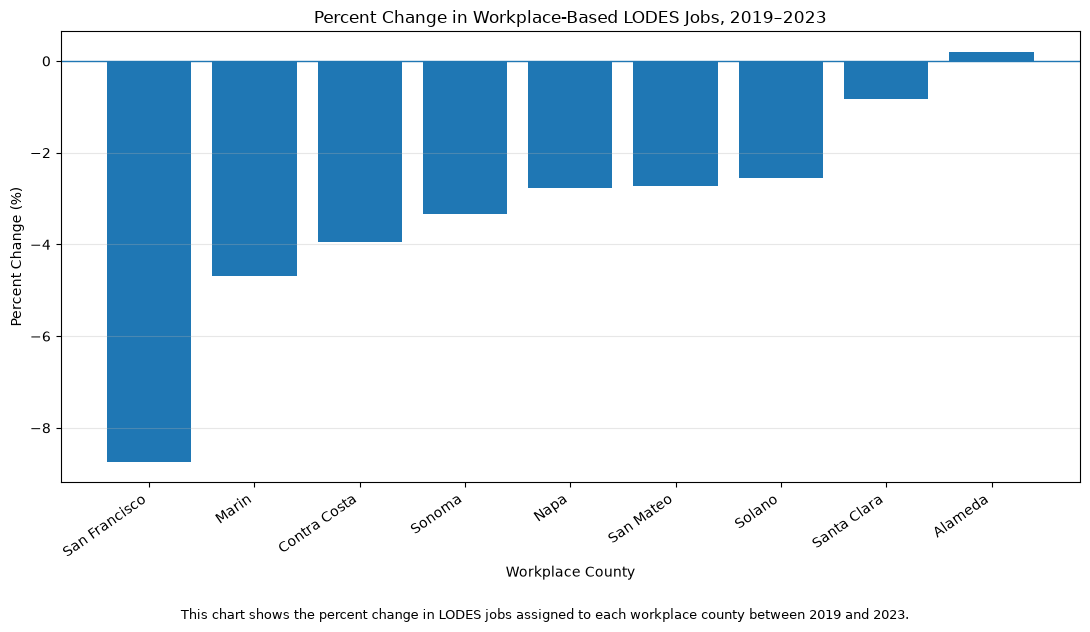

In [5]:
jobs_2019 = pd.read_csv("../data/processed/LODES_2019_county.csv")

jobs_2023 = pd.read_csv("../data/processed/LODES_2023_county.csv")

workplace_2019 = (jobs_2019.groupby("w_county")["commuters"].sum())

workplace_2023 = (jobs_2023.groupby("w_county")["commuters"].sum())

workplace_change = pd.DataFrame({"jobs_2019": workplace_2019, "jobs_2023": workplace_2023})

workplace_change["percent_change"] = ((workplace_change["jobs_2023"] - workplace_change["jobs_2019"]) / workplace_change["jobs_2019"] * 100)

workplace_change = workplace_change.sort_values("percent_change")

os.makedirs("../visualizations/figures", exist_ok=True)

plt.figure(figsize=(11, 6))

plt.bar(workplace_change.index, workplace_change["percent_change"])

plt.axhline(0, linewidth=1)

plt.title("Percent Change in Workplace-Based LODES Jobs, 2019–2023")
plt.xlabel("Workplace County")
plt.ylabel("Percent Change (%)")

plt.xticks(rotation=35, ha="right")

plt.grid(axis="y", alpha=0.3)

plt.figtext(
    0.5,
    -0.04,
    "This chart shows the percent change in LODES jobs assigned to each workplace county between 2019 and 2023.",
    ha="center",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    "../visualizations/figures/chart3_workplace_change_2019_2023.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

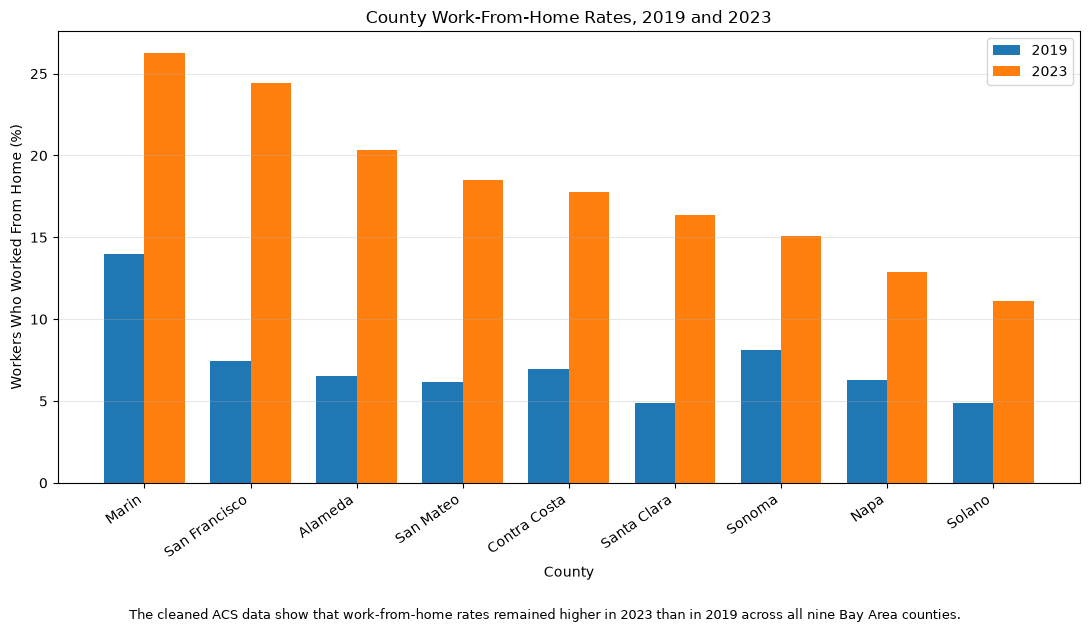

In [6]:
acs_wfh = pd.read_csv("../data/processed/ACS_WFH.csv")

if "county" not in acs_wfh.columns:
    acs_wfh = acs_wfh.rename(columns={"Unnamed: 1": "county"})

wfh_rates = acs_wfh[["county", "WFH prop 2019", "WFH prop 2023"]].copy()

wfh_rates["WFH rate 2019"] = (wfh_rates["WFH prop 2019"] * 100)

wfh_rates["WFH rate 2023"] = (wfh_rates["WFH prop 2023"] * 100)

wfh_rates = wfh_rates.sort_values("WFH rate 2023", ascending=False)

x = np.arange(len(wfh_rates))
width = 0.38

os.makedirs("../visualizations/figures", exist_ok=True)

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    wfh_rates["WFH rate 2019"],
    width,
    label="2019"
)

plt.bar(
    x + width / 2,
    wfh_rates["WFH rate 2023"],
    width,
    label="2023"
)

plt.title("County Work-From-Home Rates, 2019 and 2023")

plt.xlabel("County")
plt.ylabel("Workers Who Worked From Home (%)")

plt.xticks(
    x,
    wfh_rates["county"],
    rotation=35,
    ha="right"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.figtext(
    0.5,
    -0.04,
    "The cleaned ACS data show that work-from-home rates remained higher in 2023 than in 2019 across all nine Bay Area counties.",
    ha="center",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    "../visualizations/figures/chart4_wfh_rates_2019_2023.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

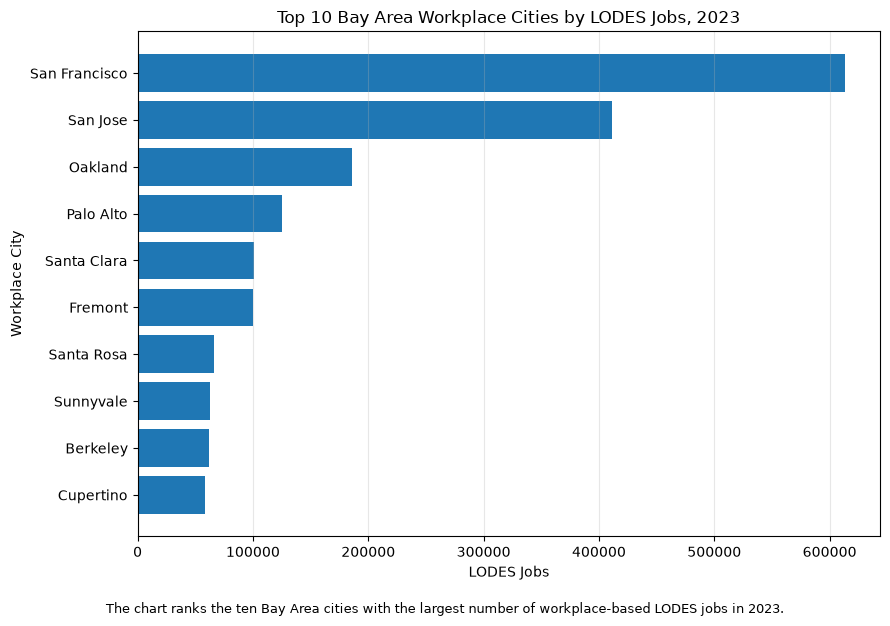

In [7]:
city_2023 = pd.read_csv("../data/processed/LODES_2023_city.csv")

city_2023 = city_2023.dropna(subset=["w_city"])

top_workplace_cities = (city_2023.groupby("w_city")["commuters"].sum().sort_values(ascending=False).head(10).sort_values())

os.makedirs("../visualizations/figures", exist_ok=True)

plt.figure(figsize=(9, 6))

plt.barh(
    top_workplace_cities.index,
    top_workplace_cities.values
)

plt.title("Top 10 Bay Area Workplace Cities by LODES Jobs, 2023")

plt.xlabel("LODES Jobs")
plt.ylabel("Workplace City")

plt.grid(axis="x", alpha=0.3)

plt.figtext(
    0.5,
    -0.03,
    "The chart ranks the ten Bay Area cities with the largest number of workplace-based LODES jobs in 2023.",
    ha="center",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    "../visualizations/figures/chart5_top_workplace_cities_2023.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()